# Visualización de datos con Seaborn

En este ejercicio vamos a ampliar el ejercicios de peatones con más gráficosde la librería `Seaborn`.

Recuerda que trabajamos con el fichero .csv de la página del Portal de Datos Abiertos del Ayuntamiento de Madrid (https://datos.madrid.es/). Desde dicha página buscamos `peatones` y nos lleva a `Aforos de peatones y bicicletas` (https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas). Aquí tenemos que descargarnos el fichero csv de peatones correspondiente al año 2020
https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads.


## Carga de datos y exploración del dataframe

Después de descargarnos el fichero `300321-3-aforos-peatones-bicicletas-csv.csv` correspondiente al año 2020  de la web https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads, lo dejamos en nuestra carpeta llamada Data y lo importamos como un dataframe llamado df.

Lo primero que tenemos que hacer es ver el contenido del fichero con una aplicación de texto plano y veo que el csv no está separado por `comas`, sino por `punto y coma` y además, utiliza la `coma` como separador decimal en LATITUD y LONGITUD. Así que se debe indicar `sep=";"` y `decimal=","` como parámetros de la carga de pandas `pd.read_csv`. 

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "./Data/300321-3-aforos-peatones-bicicletas-csv.csv",
    sep=";",
    decimal=","
)

Muestra el DataFrame para comprobar que la carga se ha realizado correctamente. Puedes escribir simplemente el nombre del objeto.

In [52]:
df.shape

(166896, 12)

### Analizar y transformar las fechas y horas

Por el trabajo del tema anterior ya sabemos que 
- `PEATONES`, `NÚMERO_DISTRITO`, `NÚMERO`y `CÓDIGO_POSTAL` son `int64`,
- `LATITUD` y `LONGITUD` son `float64`.
- resto son de tipo  object

Pero en python tenemos un tipo de datos específico para la fecha y la hora

#### Fechas 
En Python podemos trabajar con distintos tipos de datos temporales:
- `date`: representa una fecha: año, mes y día.
- `time`: representa una hora: hora, minutos, segundos.
- `datetime`: representa fecha y hora conjuntamente

Usamos `pd.to_datetime()` para convertir los tipos de los valores de la columna `FECHA`. Además, necesitamos el parámetro `dayfirst = True` para indicar a pandas que, al interpretar una fecha, el primer número corresponde al día pues la fecha está escrita con el día antes del mes.

Al ejecutar `df["FECHA"] = pd.to_datetime(df["FECHA"], dayfirst=True)` da error porque el fichero hay dos formatos diferentes en las fechas, unos es con la hora `01/01/2020 00:00` y el otro es sin hora `02/09/2020`.
Pandas ha inferido inicialmente el formato `%d/%m/%Y %H:%M` pero ha detectado un valor que no seguía este formato. Pandas nos aconseja que tomemos el formato mixto para la fecha.

In [58]:
df["FECHA"] = pd.to_datetime(
    df["FECHA"],
    dayfirst = True,
    format = "mixed"
)

# comprobamos el tipo del primer valor de la columna `FECHA`
type(df["FECHA"].iloc[0])

pandas._libs.tslibs.timestamps.Timestamp

Ahora sí que estamos trabajando con fechas reales y podemos, por ejemplo, 
extraer de FECHA una parte concreta utilizando el accesor `.dt`. Prueba primero con el año (`df["FECHA"].dt.year`), después con el mes y finalmente con el nombre del día de la semana.

#### Horas

Ahora vamos con la columna `HORA` que aparece como texto de la forma `00:00` y `01:00`. Estos valores
podemos convertirlos a un tipo de hora de pandas pero, pandas no tiene una función `pd.to_time()`. Necesitamos hacer un `pd.to_datetime()` con formato `%H:%M` como parámetro. Finalmente, aplicamos `pd.to_datetime().dt.time` para quedarnos únicamente con la parte de la hora.


In [61]:
df["HORA"] = pd.to_datetime(
    df["HORA"],
    format="%H:%M"
).dt.time

type(df["HORA"].iloc[0])

datetime.time

### Seleccionar ciertas columnas de la tabla, las que me interesan


Crea un nuevo DataFrame `df_1` seleccionando únicamente las columnas:
`FECHA`, `HORA`, `PEATONES`, `DISTRITO`, `NOMBRE_VIAL` y `NÚMERO`.
Para seleccionar varias columnas necesitas una lista de nombres dentro de los corchetes.
Usa `.copy()` para crear un nuevo DataFrame independiente.


In [63]:
df_1 = df[["FECHA", "HORA", "PEATONES", "DISTRITO", "NOMBRE_VIAL", "NÚMERO"]].copy()

### Cambiar el nombre de la columna `NOMBRE_VIAL`por `DIRECCIÓN`. 

Utiliza `rename()` para cambiar el nombre de `NOMBRE_VIAL` por `DIRECCIÓN`.
Después puedes consultar `df_1.columns` para comprobar el cambio.


In [68]:
df_1 = df_1.rename(columns={"NOMBRE_VIAL": "DIRECCIÓN"})
df_1.columns

Index(['FECHA', 'HORA', 'PEATONES', 'DISTRITO', 'DIRECCIÓN', 'NÚMERO'], dtype='object')



## Gráficos facetados o gráficos de paneles múltiples (small multiples).

Permiten representar el mismo tipo de gráfico en varios paneles, dividiendo los datos según una variable ***categórica***. Por ejemplo, podemos tener un gráfico independiente para cada distrito de Madrid.

En concreto, vamos a utilizar la ***biblioteca Seaborn*** que utiliza:


| Función | `kind` | Nombre del gráfico | ¿Para qué sirve? |
|---|---|---|---|
| `sns.relplot()` | `"line"` | Gráfico de líneas | Estudiar la evolución de una variable y las tendencias. |
| | `"scatter"` | Diagrama de dispersión | Estudiar la relación entre dos variables numéricas. |
| `sns.catplot()` | `"bar"` | Gráfico de barras | Comparar la media de una variable numérica entre categorías. |
| | `"box"` | Diagrama de caja | Comparar distribuciones y medianas. |
| | `"violin"` | Diagrama de violín | Comparar la forma y densidad de las distribuciones. |
| | `"strip"` | Diagrama de puntos | Mostrar las observaciones individuales. |
| | `"swarm"` | Diagrama de puntos distribuidos | Visualizar observaciones individuales evitando solapamientos. |
| | `"point"` | Gráfico de puntos | Comparar medias y sus intervalos de confianza. |
| | `"boxen"` | Diagrama de cajas ampliado | Analizar distribuciones con muchos datos. |
| | `"count"` | Gráfico de frecuencias | Contar observaciones de cada categoría. |
| `sns.displot()` | `"hist"` | Histograma | Analizar la frecuencia de los valores de una variable numérica. |
| | `"kde"` | Gráfico de densidad | Representar una estimación suavizada de la distribución. |
| | `"ecdf"` | Función de distribución acumulada empírica | Mostrar la proporción de observaciones menores o iguales que cada valor. |

</br>


### sns.relplot(): estudiar relaciones

Se utiliza cuando queremos estudiar la relación entre variables, normalmente numéricas o temporales.

***Ejemplo:*** estudiar la evolución mensual de peatones diferenciando los distritos.

</br>

</br>

Para utilizar la *biblioteca Seaborn* se necesitan resetear los índices resultados del `groupby`.
Si no se resetean los índices, el resultado es una serie, con `reset_index()` el resultado es un dataframe. 

Creamos un panel para cada distrito con `sns.relplot()`. Se puede sustituir `kind="line"` por `kind = "scatter"`. Son las dos opciones disponibles para esta función en *Seaborn*. También puedes omitir `kind`, porque `scatter` es el valor predeterminado.

</br>

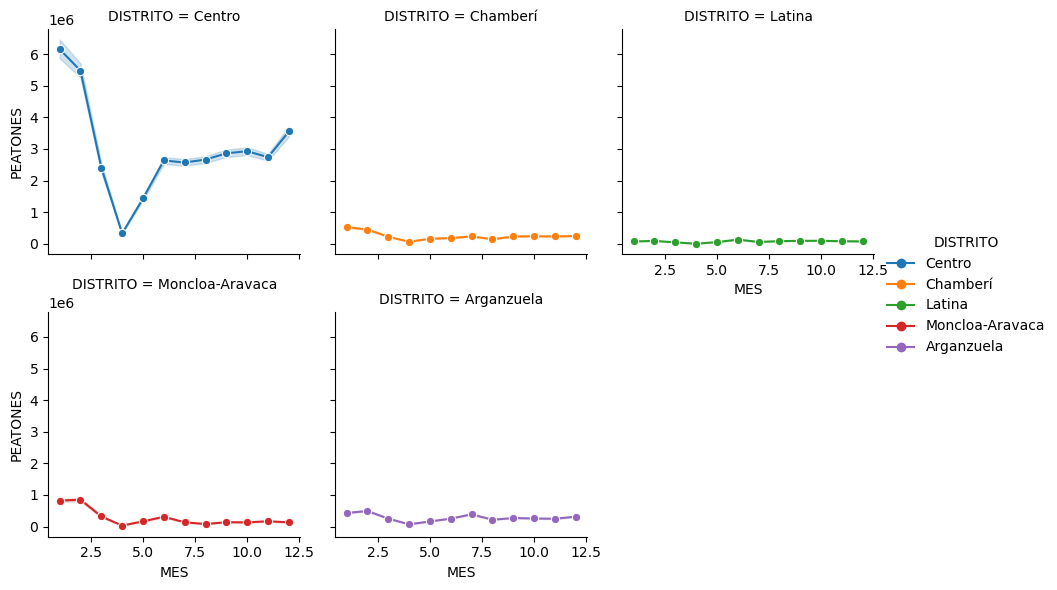

In [248]:
import seaborn as sns

# Hacemos una columna nueva con el mes de cada observación
df_1["MES"] = df_1["FECHA"].dt.month

sns.relplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",    # Crea un panel por distrito
    col_wrap = 3,        # Coloca 3 gráficos por fila
    kind = "line",       # tipo de gráfico
    marker = "o",
    height = 3,          # Altura de cada panel
    estimator = "sum",   # suma el número de peatones de cada mes y distrito
    #errorbar = None     # intervalos de incertidumbre.
    hue = "DISTRITO"     # representa cada distrito con un color diferente.
)

plt.show()

</br>

Obtendremos un gráfico de puntos-líneas independiente para cada distrito.

Si queremos mostrar los meses del 1 al 12 en todos los paneles:

</br>

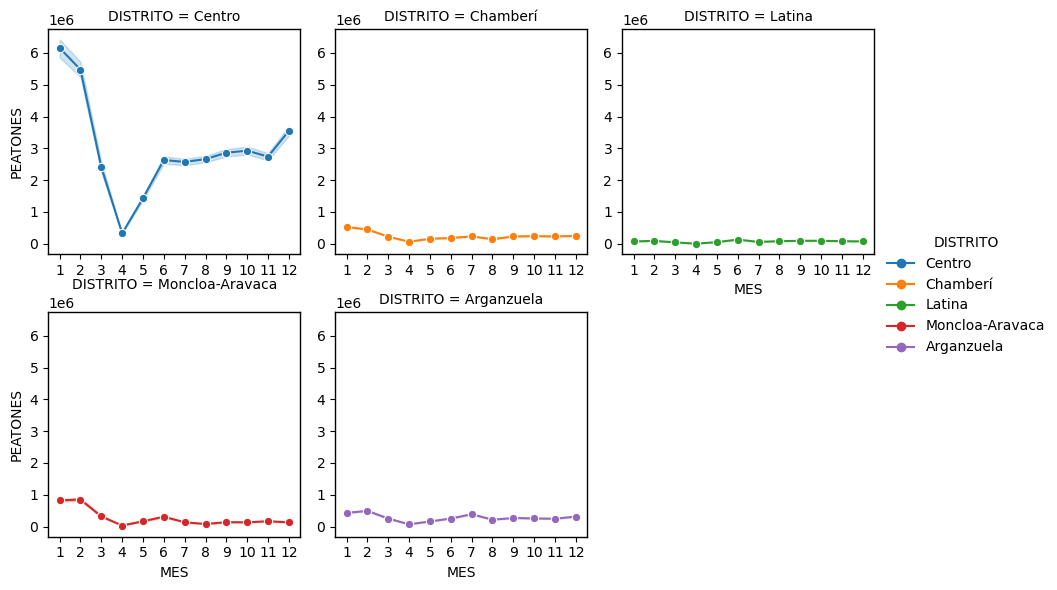

In [257]:
import seaborn as sns

# Hacemos una columna nueva con el mes de cada observación
df_1["MES"] = df_1["FECHA"].dt.month

g = sns.relplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",    # Crea un panel por distrito
    col_wrap = 3,        # Coloca 3 gráficos por fila
    kind = "line",       # tipo de gráfico
    marker = "o",
    height = 3,          # Altura de cada panel
    estimator = "sum",   # suma el número de peatones de cada mes y distrito
    #errorbar = None     # intervalos de incertidumbre.
    hue = "DISTRITO"     # representa cada distrito con un color diferente.
)

# Mostrar los meses del 1 al 12 en todos los paneles
for ax in g.axes.flat:         # g es el sns anteroior
    # Mostrar los meses en todos los paneles
    ax.set_xticks(range(1, 13))
    ax.tick_params(axis="x", labelbottom=True)

    # Mostrar las etiquetas del eje Y
    ax.tick_params(axis="y", labelleft=True)

    # Dibujar un recuadro alrededor de cada gráfico
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1)
        spine.set_color("black")

plt.show()

## sns.catplot(): comparar categorías

Se utiliza cuando queremos comparar una variable numérica entre diferentes categorías.

Puede representar diagramas de barras, cajas, violines y puntos, entre otros.

***Ejemplo***: comparar la distribución de los peatones en los diferentes distritos y meses.



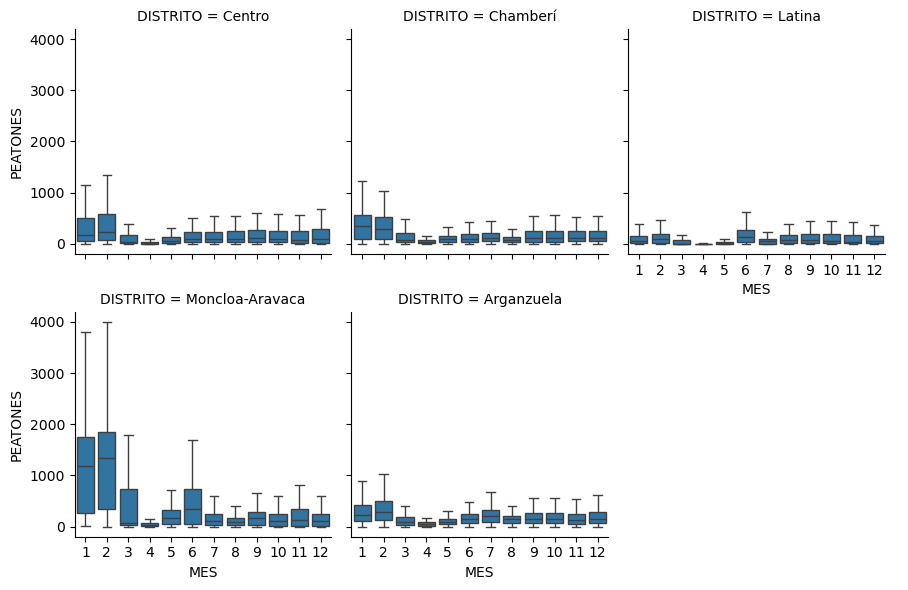

In [179]:
sns.catplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",
    col_wrap = 3,
    kind = "box",
    showfliers = False,
    height = 3
)

plt.show()


En este caso `MES`es la categoría que comparamos (enero, febrero, etc.), `PEATONES` es una variable numérica cuya distribución estamos estudiando y `DISTRITO`es la variable que permite separar los datos en diferentes paneles. De esta forma, cada panel representa un distrito y muestra un diagrama de caja por mes. 

</br>

***Ejemplo:*** podemos comparar la media de peatones por distrito:

***Observación***: `kind = "bar"` **muestra por defecto la media**, no la suma de los peatones. Si queremos comparar totales, debemos agrupar previamente los datos.



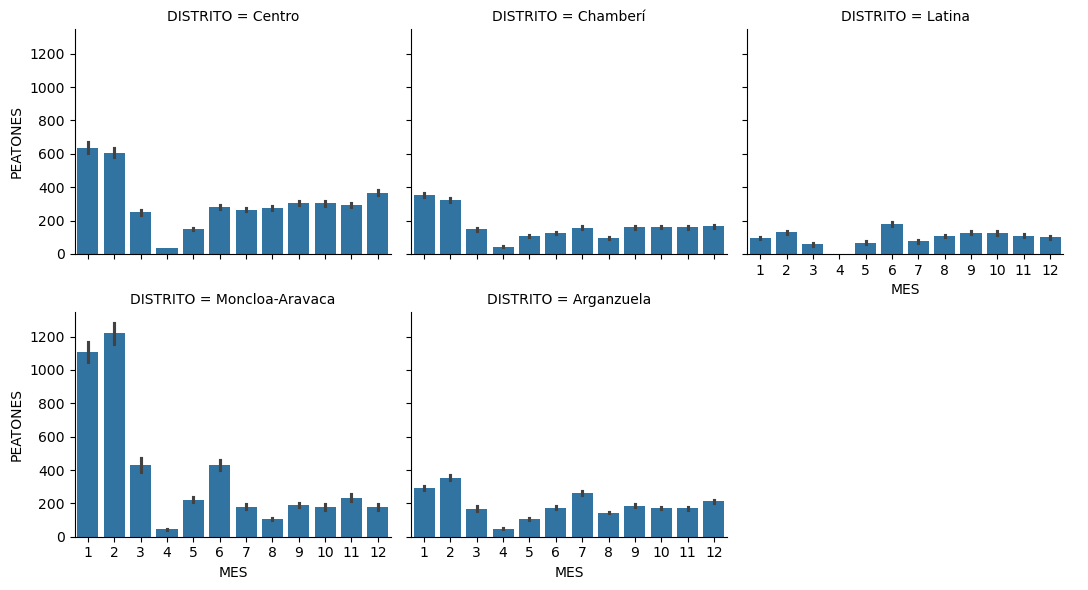

In [212]:
sns.catplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",
    kind = "bar",
    col_wrap = 3,
    height = 3,
    aspect = 1.2
)

plt.show()

## sns.displot(): estudiar distribuciones

Se utiliza cuando queremos analizar cómo se distribuyen los valores de una variable numérica.

Sus representaciones más habituales son:
- kind="hist": histograma.
- kind="kde": estimación suavizada de la distribución.
- kind="ecdf": función de distribución acumulada empírica.

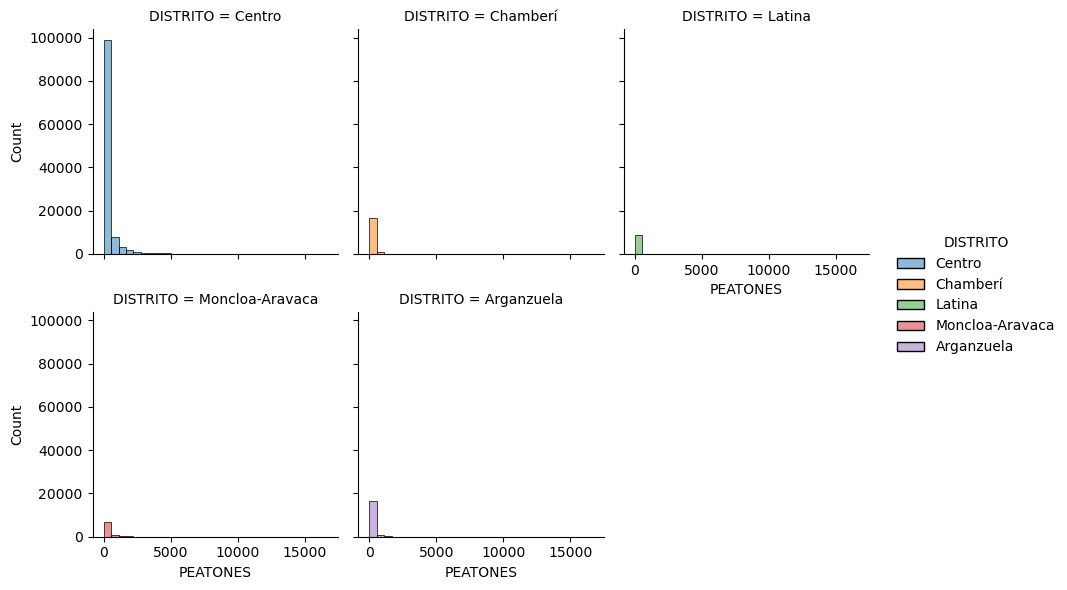

In [207]:
sns.displot(
    data=df_1,
    x="PEATONES",
    col="DISTRITO",
    col_wrap=3,
    kind="hist",
    bins=30,
    height=3,
    hue="DISTRITO"
)

plt.show()

In [120]:

df_1["DIA_SEMANA"] = df_1["FECHA"].dt.dayofweek.map({
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
})

peatones_dia_distrito = (
    df_1.groupby(["DIA_SEMANA", "DISTRITO"])["PEATONES"]
    .sum()
    .reset_index()
)


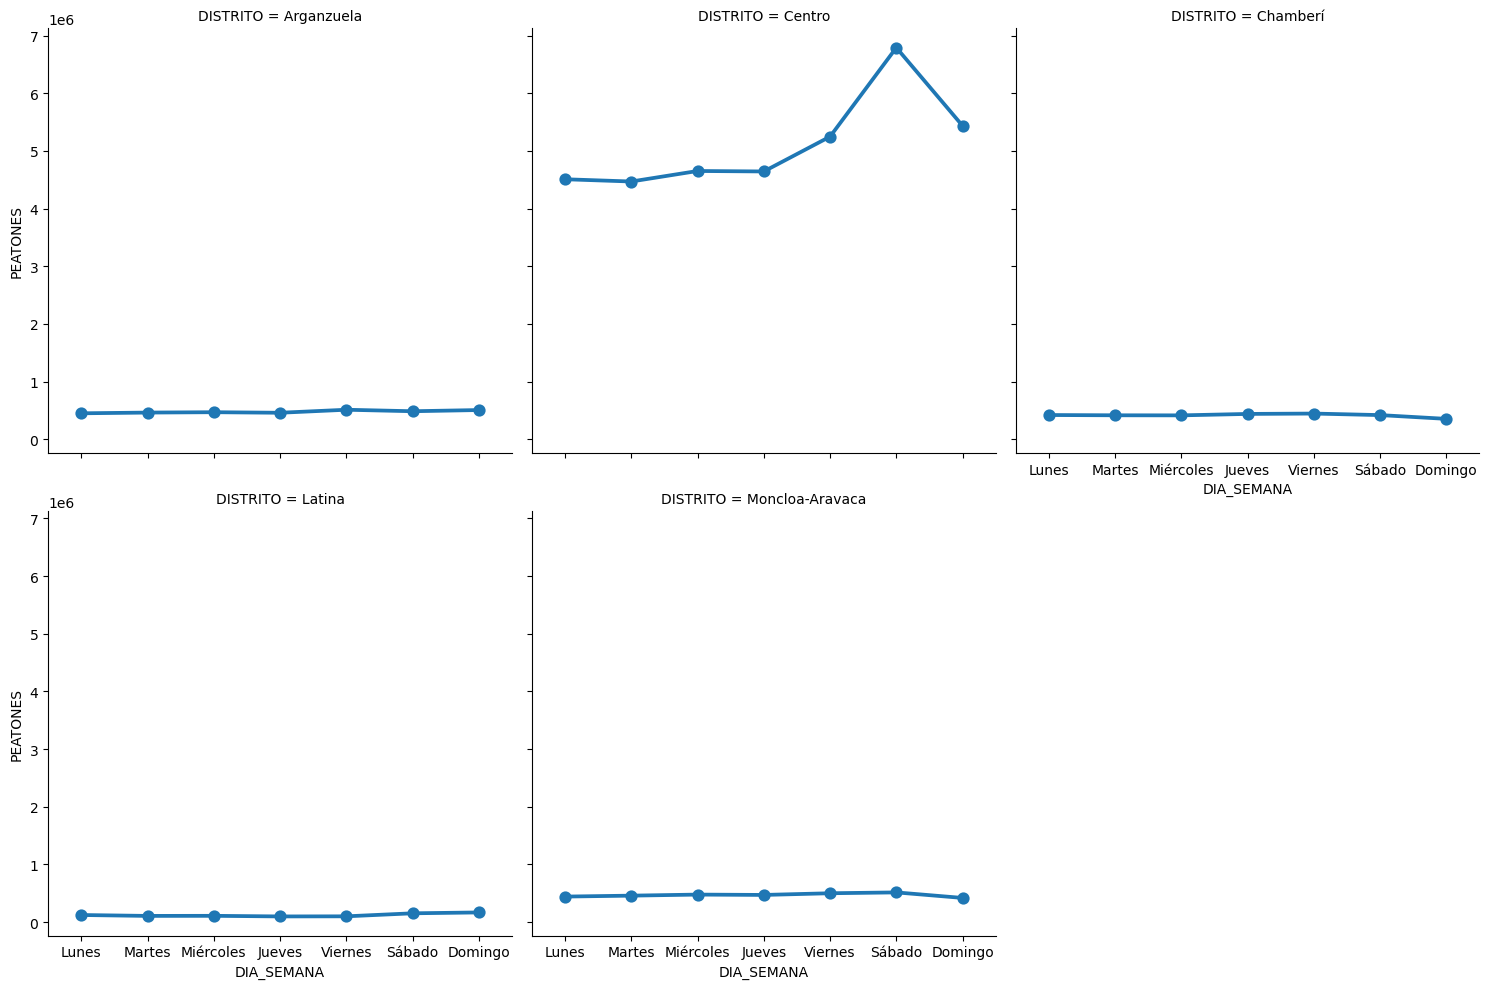

In [126]:
sns.catplot(
    data = peatones_dia_distrito,
    x = "DIA_SEMANA",
    y = "PEATONES",
    col = "DISTRITO",
    col_wrap = 3,
    kind = "point",        # "bar", "box", "violin", "strip", "swarm", "point", "boxen", "count"   
    order = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
)

plt.show()

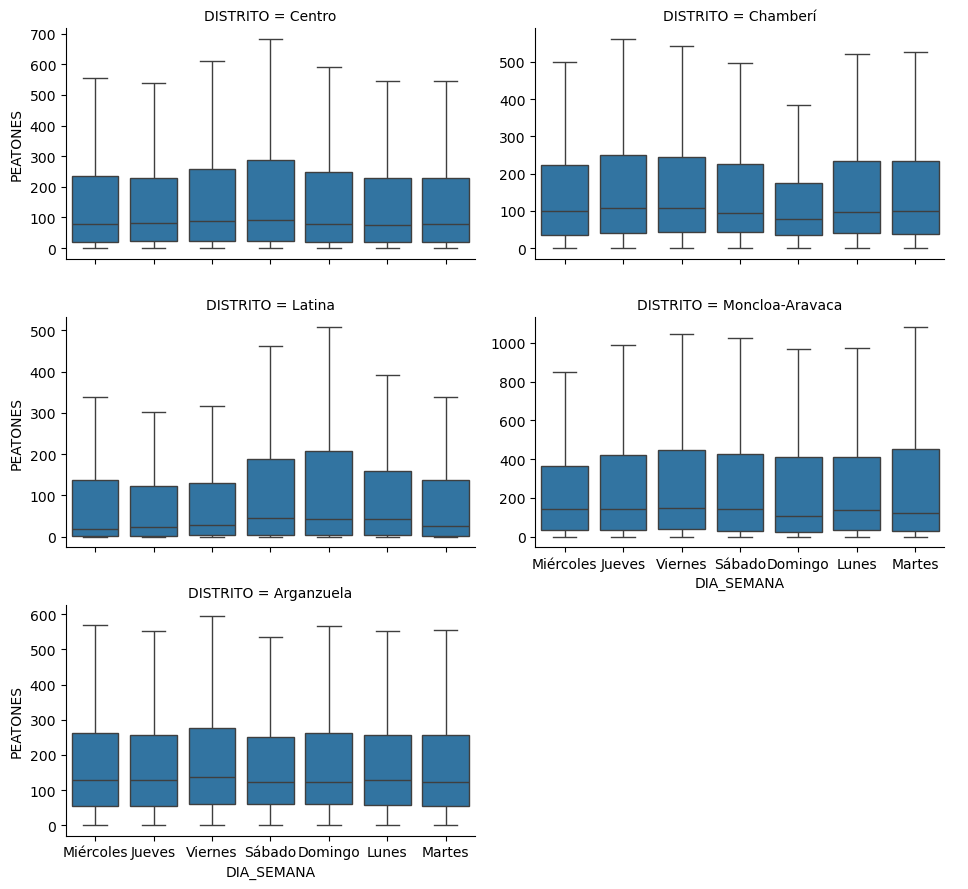

In [142]:


sns.catplot(
    data = df_1,
    x = "DIA_SEMANA",
    y = "PEATONES",
    col = "DISTRITO",
    col_wrap = 2,
    kind = "box",
    showfliers = False,   # Oculta los valores atípicos
    sharey = False,       # Escala vertical
    height = 3,           # Altura de cada panel
    aspect = 1.6          # Relación entre anchura y altura
)

plt.show()